# General

In [1]:
import os
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(42)
for gpu in tf.config.list_physical_devices('GPU'):
    tf.config.experimental.set_memory_growth(gpu, True)

# Data

In [2]:
(x_train_raw, y_train), (x_test_raw, y_test) = keras.datasets.mnist.load_data()

In [3]:
def reshape_and_normalize(images):
    images = images.reshape((-1, 28, 28, 1)).astype('float32')
    images = images / 255.0
    return images

In [4]:
training_images = reshape_and_normalize(x_train_raw)
training_labels = y_train
test_images = reshape_and_normalize(x_test_raw)
print('Training:', training_images.shape, 'Test:', test_images.shape)
print('Pixel range:', training_images.min(), training_images.max())

Training: (60000, 28, 28, 1) Test: (10000, 28, 28, 1)
Pixel range: 0.0 1.0


# Model

Use one convolution and one pooling layer, with fewer than 1,000,000 parameters.

In [7]:
model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(16, 3, activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.Dense(10, activation='softmax')
])
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model_params = model.count_params()
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 26, 26, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 13, 13, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2704)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       692,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 695,210 (2.65 MB)

 Trainable params: 695,210 (2.65 MB)

 Non-trainable params: 0 (0.00 B)

# Training

Stop at 99.5% training accuracy, before epoch 10.

In [8]:
class myCallback(keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        accuracy = (logs or {}).get('accuracy')
        if accuracy is not None and accuracy >= 0.995:
            print('Reached 99.5% accuracy so cancelling training!')
            self.model.stop_training = True

In [9]:
callbacks = myCallback()
hist = model.fit(training_images, training_labels, epochs=10, batch_size=128, callbacks=[callbacks], verbose=2)

Epoch 1/10
469/469 - 6s - 13ms/step - accuracy: 0.9366 - loss: 0.2210
Epoch 2/10
469/469 - 2s - 4ms/step - accuracy: 0.9789 - loss: 0.0705
Epoch 3/10
469/469 - 1s - 3ms/step - accuracy: 0.9863 - loss: 0.0462
Epoch 4/10
469/469 - 1s - 2ms/step - accuracy: 0.9906 - loss: 0.0335
Epoch 5/10
469/469 - 1s - 2ms/step - accuracy: 0.9931 - loss: 0.0246
Epoch 6/10
Reached 99.5% accuracy so cancelling training!
469/469 - 1s - 3ms/step - accuracy: 0.9954 - loss: 0.0178


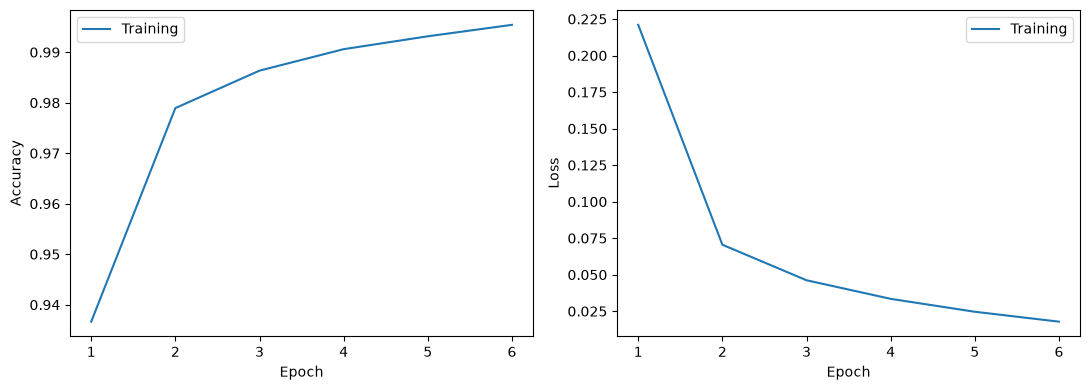

In [13]:
history = pd.DataFrame(hist.history)
epochs = np.arange(1, len(history) + 1)

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric in zip(axs, ['accuracy', 'loss']):
    ax.plot(epochs, history[metric], label='Training')
    if f'val_{metric}' in history:
        ax.plot(epochs, history[f'val_{metric}'], label='Validation')
    ax.set_xlabel('Epoch')
    ax.set_ylabel(metric.capitalize())
    ax.legend()
plt.tight_layout()
plt.show()

# Results

In [16]:
loss, accuracy = model.evaluate(test_images, y_test, verbose=0)
result = {
    'part': 'part3',
    'epochs': len(hist.epoch),
    'parameters': model_params,
    'train_accuracy': hist.history['accuracy'][-1],
    'test_loss': loss,
    'test_accuracy': accuracy
}
display(pd.DataFrame([result]))

,part,epochs,parameters,train_accuracy,test_loss,test_accuracy
0,part3,6,695210,0.995417,0.040834,0.9874


# Saving

In [19]:
model.save('models/part3.keras')

# Summary

Мережа з одним згортковим шаром і одним шаром MaxPooling досягла **99.63%** навчальної точності за **6 епох**. Умову 99.5% раніше десятої епохи виконано. Модель має **695,210 параметрів**, менше мільйона.

Тестова точність - **98.63%**, порівняно з 97.78% у частині 1. Згортка враховує просторове розташування пікселів і використовує спільні фільтри для локальних ознак. У цьому запуску вона покращила розпізнавання, хоча поріг навчальної точності сам по собі цього не гарантує.